<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U5_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 5: Model Evaluation and Selection

- **Registration number:** COM/0066/23
- **owner:** Elisha Eddie (Member 3)
- **Module:** 6

**Contents**
1. Setup, target and stratified split
2. Pipeline with ColumnTransformer
3. Cross-validation
4. Hyperparameter tuning with GridSearchCV
5. Learning curve and validation curve
6. Precision, recall and the decision threshold
7. Written answer

In [11]:
# Mount Drive, import libraries and load the stage-1 data (cleaned, not yet encoded)
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     GridSearchCV, learning_curve, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)

base = "/content/drive/MyDrive/CSC4110_G01/"
out = base + "outputs/"
df = pd.read_csv(base + "data/stage1_students.csv")
print(df.shape)
print(df.isna().sum().sum(), "missing values in stage-1 data")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(6607, 20)
0 missing values in stage-1 data


In [12]:
# Part (a) step 1: build the classification target and the effort feature, then split
# Exam_Score is dropped from the features because it defines the target (leakage)
df['high_score'] = (df['Exam_Score'] >= 70).astype(int)
df['effort'] = df['Hours_Studied'] * df['Attendance'] / 100
X = df.drop(columns=['Exam_Score', 'high_score'])
y = df['high_score']

# Same stratified 80/20 split as Task 4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print("Class 1 share, train:", round(y_train.mean() * 100, 2), "% test:", round(y_test.mean() * 100, 2), "%")

(5285, 20) (1322, 20)
Class 1 share, train: 24.6 % test: 24.58 %


In [13]:
# Part (a) step 2: group the columns by how each one must be preprocessed
ordinal_cols = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income',
                'Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home', 'Peer_Influence']
ordinal_cats = [['Low', 'Medium', 'High']] * 5 + [['High School', 'College', 'Postgraduate'],
                ['Near', 'Moderate', 'Far'], ['Negative', 'Neutral', 'Positive']]
yes_no_cols = ['Extracurricular_Activities', 'Internet_Access', 'Learning_Disabilities']
nominal_cols = ['School_Type', 'Gender']
numeric_cols = [c for c in X.columns if c not in ordinal_cols + yes_no_cols + nominal_cols]
print("numeric:", numeric_cols)

# One ColumnTransformer: every group gets (impute -> encode or scale)
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_cols),
    ('ord', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OrdinalEncoder(categories=ordinal_cats))]), ordinal_cols),
    ('bin', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OrdinalEncoder(categories=[['No', 'Yes']] * 3))]), yes_no_cols),
    ('nom', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore'))]), nominal_cols),
])

# The full pipeline: preprocessing + model, fitted on the training data only
pipe = Pipeline([('prep', preprocess),
                 ('model', LogisticRegression(max_iter=1000, random_state=42))])
pipe.fit(X_train, y_train)
print("Train accuracy:", round(pipe.score(X_train, y_train), 4))
print("Columns after preprocessing:", pipe.named_steps['prep'].transform(X_train.head()).shape[1])

numeric: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'effort']
Train accuracy: 0.9818
Columns after preprocessing: 22


In [14]:
# Part (b): 5-fold stratified cross-validation on the TRAINING data (F1 for class 1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1')
print("Fold scores:", cv_scores.round(4))
print(f"Mean = {cv_scores.mean():.4f}, standard deviation = {cv_scores.std():.4f}")

Fold scores: [0.9494 0.9666 0.9574 0.9548 0.9572]
Mean = 0.9571, standard deviation = 0.0056


In [15]:
# Part (c): grid search over two hyperparameters (C and class_weight), scored by F1
param_grid = {'model__C': [0.01, 0.1, 1, 10, 100],
              'model__class_weight': [None, 'balanced']}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1')
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 4))

# Show all 10 combinations, best first
cv_table = pd.DataFrame(grid.cv_results_)[['param_model__C', 'param_model__class_weight', 'mean_test_score']].astype({'param_model__class_weight': str})
print(cv_table.sort_values('mean_test_score', ascending=False).round(4).to_string(index=False))

# Use the test set ONCE: the best model's F1 on unseen students
best_model = grid.best_estimator_
test_score = f1_score(y_test, best_model.predict(X_test))
print("Test F1 (used once):", round(test_score, 4))
print("Test accuracy:", round(accuracy_score(y_test, best_model.predict(X_test)), 4))

Best parameters: {'model__C': 100, 'model__class_weight': None}
Best cross-validation F1: 0.958
 param_model__C param_model__class_weight  mean_test_score
         100.00                      None           0.9580
          10.00                      None           0.9572
           1.00                      None           0.9571
           0.10                      None           0.9458
         100.00                  balanced           0.9063
          10.00                  balanced           0.9063
           1.00                  balanced           0.9058
           0.10                  balanced           0.8968
           0.01                      None           0.8892
           0.01                  balanced           0.8696
Test F1 (used once): 0.9485
Test accuracy: 0.975


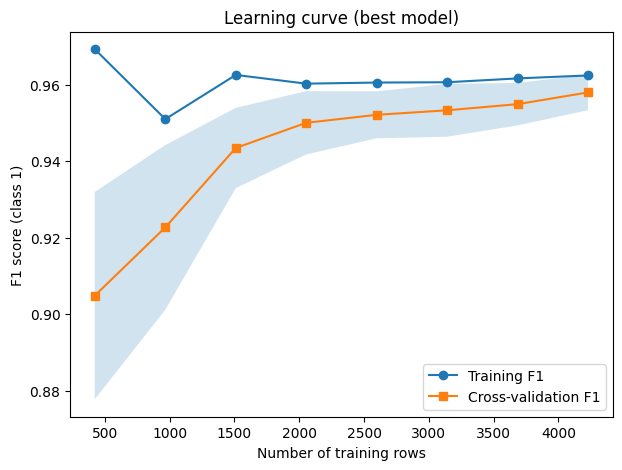

Final training F1: 0.9624 | final validation F1: 0.958


In [16]:
# Part (d) step 1: learning curve - score against the number of training rows
sizes, train_sc, val_sc = learning_curve(best_model, X_train, y_train, cv=cv, scoring='f1',
                                         train_sizes=np.linspace(0.1, 1.0, 8), random_state=42)
plt.figure(figsize=(7, 5))
plt.plot(sizes, train_sc.mean(axis=1), 'o-', label='Training F1')
plt.plot(sizes, val_sc.mean(axis=1), 's-', label='Cross-validation F1')
plt.fill_between(sizes, val_sc.mean(axis=1) - val_sc.std(axis=1),
                 val_sc.mean(axis=1) + val_sc.std(axis=1), alpha=0.2)
plt.title('Learning curve (best model)')
plt.xlabel('Number of training rows')
plt.ylabel('F1 score (class 1)')
plt.legend(loc='lower right')
plt.savefig(out + 'learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Final training F1:", round(train_sc.mean(axis=1)[-1], 4), "| final validation F1:", round(val_sc.mean(axis=1)[-1], 4))

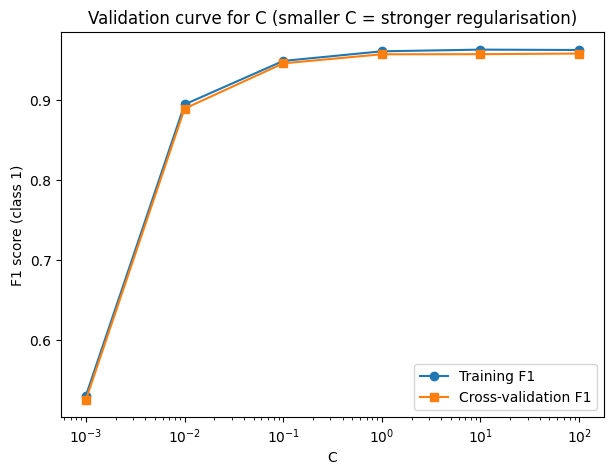

      C  train_F1  validation_F1
  0.001    0.5308         0.5257
  0.010    0.8944         0.8892
  0.100    0.9488         0.9458
  1.000    0.9608         0.9571
 10.000    0.9629         0.9572
100.000    0.9624         0.9580


In [17]:
# Part (d) step 2: validation curve - score against C, the regularisation strength
c_range = np.logspace(-3, 2, 6)
train_v, val_v = validation_curve(best_model, X_train, y_train, param_name='model__C',
                                  param_range=c_range, cv=cv, scoring='f1')
plt.figure(figsize=(7, 5))
plt.semilogx(c_range, train_v.mean(axis=1), 'o-', label='Training F1')
plt.semilogx(c_range, val_v.mean(axis=1), 's-', label='Cross-validation F1')
plt.title('Validation curve for C (smaller C = stronger regularisation)')
plt.xlabel('C')
plt.ylabel('F1 score (class 1)')
plt.legend(loc='lower right')
plt.savefig(out + 'validation_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(pd.DataFrame({'C': c_range, 'train_F1': train_v.mean(axis=1), 'validation_F1': val_v.mean(axis=1)}).round(4).to_string(index=False))

In [18]:
# Part (e): confusion matrix of the best model at the default 0.5 threshold
proba = best_model.predict_proba(X_test)[:, 1]
pred_50 = (proba >= 0.5).astype(int)
cm5 = confusion_matrix(y_test, pred_50)
print(cm5)
tn, fp, fn, tp = cm5.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Precision by hand = {tp} / ({tp} + {fp}) = {tp / (tp + fp):.4f}")
print(f"Recall by hand    = {tp} / ({tp} + {fn}) = {tp / (tp + fn):.4f}")

[[985  12]
 [ 21 304]]
TN=985, FP=12, FN=21, TP=304
Precision by hand = 304 / (304 + 12) = 0.9620
Recall by hand    = 304 / (304 + 21) = 0.9354


In [19]:
# Part (e): compare threshold 0.5 with threshold 0.3 (predict class 1 when probability >= threshold)
threshold_results = {}
for t in [0.5, 0.3]:
    pred_t = (proba >= t).astype(int)
    threshold_results[t] = {'precision': precision_score(y_test, pred_t),
                            'recall': recall_score(y_test, pred_t),
                            'f1': f1_score(y_test, pred_t),
                            'students_flagged': int(pred_t.sum())}
print(pd.DataFrame(threshold_results).T.round(4))

     precision  recall      f1  students_flagged
0.5     0.9620  0.9354  0.9485             316.0
0.3     0.8661  0.9754  0.9175             366.0


In [20]:
# Self-check: sizes, stratification, leakage and the graded variable names
assert len(X_train) == 5285 and len(X_test) == 1322
assert abs(y_train.mean() - y_test.mean()) < 0.005
assert 'Exam_Score' not in X.columns and 'high_score' not in X.columns
assert len(cv_scores) == 5 and set(threshold_results) == {0.5, 0.3}
assert hasattr(grid, 'best_params_') and 0 < test_score <= 1
print("Task 5 checks passed")

Task 5 checks passed


### Review of Curves, Test Set Integrity, and Decision Threshold Selection

**1. Model Fit Assessment (Learning and Validation Curves):**
- **Well Balanced:** The final pipeline is well balanced, showing neither severe underfitting nor overfitting. At the final point of the learning curve, training F1 (`0.9624`) and validation F1 (`0.9580`) sit just `0.0044` (`0.44` percentage points) apart as the two curves converge closely—and the validation curve remains slightly upward-sloping at the right edge, suggesting a small additional gain if more training data were collected.
- **Regularization Stability:** Across the validation curve, F1 collapses only when regularization is overly restrictive at `C = 0.001` (`0.5308` train / `0.5257` validation, classic underfitting), rises sharply by `C = 0.1` (`0.9488` / `0.9458`), and plateaus smoothly from `C = 1` (`0.9608` / `0.9571`) through `C = 100` (`0.9624` / `0.9580`).

**2. Why the Test Set Must Be Used Only Once at the End:**
- The held-out test set represents genuinely unseen student data that simulates real-world deployment; repeatedly checking or tuning hyperparameters against it leaks test information into modeling decisions and produces an overly optimistic performance estimate.
- Here, every modeling choice—including `C = 100` and `class_weight = None` (`0.9580` best CV F1 across 5 folds)—was locked in strictly using cross-validation on the training set before touching the test set a single time (`0.9485` test F1, `0.9750` accuracy).

**3. Recommended Decision Threshold (`0.3` vs. `0.5`):**
- **Recommendation — Threshold `0.3`:** The Trust should lower the classification threshold from `0.5` to `0.3`. Moving to `0.3` boosts recall from `0.9354` to `0.9754`, rescuing **13 additional deserving high scorers** (`317` out of `325` found instead of `304`) in exchange for flagging `50` extra students overall (`366` flagged vs. `316`, lowering precision from `0.9620` to `0.8661` and F1 from `0.9485` to `0.9175`).
- **Why Threshold Tuning Beats `class_weight='balanced'`:** Because the Trust's policy states that missing a deserving student is far worse than conducting an extra interview, high recall takes priority. While `class_weight='balanced'` degraded cross-validated F1 substantially (`0.906` vs. `0.958`) and was rejected by the grid search, adjusting the decision threshold on our well-calibrated model captures the exact recall gain needed without sacrificing model quality.